# Counting hot days with ERA5-Land 🔥
### Copernicus Climate Change Service · ERA5-Land · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/unicef/hot_days_era5land.ipynb)

UNICEF's **Children's Climate Risk Report 2026** used **ERA5-Land**, at about 9 km, to count extremely hot days
above 35 °C for every place on Earth. This notebook does the same count for one country and one season, here
**Pakistan in May and June 2026**, and compares it with an earlier year.

*In Google Colab? Press **Runtime → Run all**. The Climate Data Store queues requests, so step 2 can take a few minutes.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open too, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the dataset page and accept its licence (Download tab, bottom of the page). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.
   It is kept only for this Colab session and is not saved in the notebook.

In [2]:
import os
from getpass import getpass
if not os.path.exists(os.path.expanduser("~/.cdsapirc")):
    key = getpass("Copernicus API key: ")
    for url, rc in (("https://cds.climate.copernicus.eu/api", "~/.cdsapirc"),
                    ("https://ads.atmosphere.copernicus.eu/api", "~/.adsapirc")):
        with open(os.path.expanduser(rc), "w") as f:
            f.write(f"url: {url}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the place, the season and the years

In [4]:
PLACE     = "Pakistan"
AREA      = [37.5, 60.5, 23.5, 78]           # north, west, south, east
MONTHS    = ["05", "06"]
YEARS     = ["1996", "2026"]                 # thirty years apart
THRESHOLD = 35                               # °C, as in the Children's Climate Risk Report
TIMEZONE  = "utc+05:00"                      # the local day
CITIES    = [("Jacobabad", 28.282, 68.438), ("Lahore", 31.520, 74.359), ("Karachi", 24.861, 67.010),
             ("Peshawar", 34.015, 71.524)]

## 2 · Get the daily maximum temperature

The *daily statistics* dataset computes each day's maximum from the hourly ERA5-Land data for you.

In [5]:
hot = {}
for year in YEARS:
    tmax = ekd.from_source("cds", "derived-era5-land-daily-statistics", {
        "variable": "2m_temperature", "year": year, "month": MONTHS, "day": [f"{d:02d}" for d in range(1, 32)],
        "daily_statistic": "daily_maximum", "time_zone": TIMEZONE, "frequency": "1_hourly", "area": AREA}).to_xarray()
    t = tmax[list(tmax.data_vars)[0]] - 273.15
    tdim = [d for d in t.dims if d not in ("latitude", "longitude")][0]
    hot[year] = (t >= THRESHOLD).sum(tdim).where(np.isfinite(t.isel({tdim: 0})))
    print(f"{year}: {float(hot[year].mean()):.0f} days at or above {THRESHOLD} °C on average across the box")

1996: 28 days at or above 35 °C on average across the box


2026: 35 days at or above 35 °C on average across the box


## 3 · Map both years

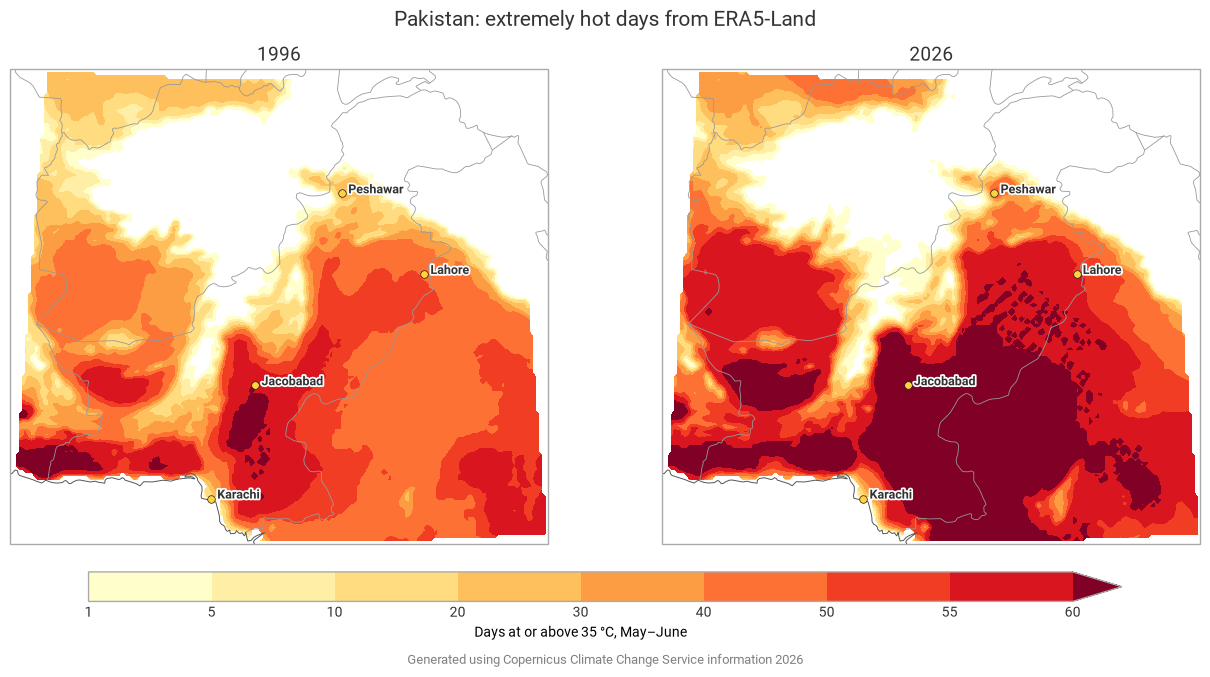

In [6]:
style = ekp.styles.Style(levels=[1, 5, 10, 20, 30, 40, 50, 55, 60], colors="YlOrRd", extend="max")   # 61 = every day
fig = ekp.Figure(rows=1, columns=len(YEARS), figsize=(13, 6))
for col, year in enumerate(YEARS):
    m = fig.add_map(0, col, domain=[AREA[1], AREA[3], AREA[2], AREA[0]])
    m.contourf(hot[year], style=style)
    m.coastlines(linewidth=0.7); m.borders(linewidth=0.6)
    for name, la, lo in CITIES:
        m.scatter(x=[lo], y=[la], s=30, color="#ffd23f", edgecolors="#1a1a1a", zorder=10)
        m.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=9, fontweight="bold", zorder=11,
                  path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    m.title(year, fontsize=14)
fig.legend(label=f"Days at or above {THRESHOLD} °C, May–June")
fig.title(f"{PLACE}: extremely hot days from ERA5-Land", fontsize=15)
fig.attribution("Generated using Copernicus Climate Change Service information 2026")
fig.save("hot_days_era5land.png")
fig.show()

## 4 · Your turn 🌍

- **A thirty-year normal:** loop `YEARS` over 1991–2020 and average, the baseline ECMWF and WMO use.
- **Hot nights:** `daily_statistic = "daily_minimum"` and a threshold of 25 °C; children sleep badly in hot nights.
- **Another place:** the Sahel (`AREA = [24, 13, 7, 24]` for Chad), or anywhere on land.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0 for these datasets). Credit:
*Generated using Copernicus Climate Change Service / Atmosphere Monitoring Service information [year].*
ECMWF runs both services for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)